In [3]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

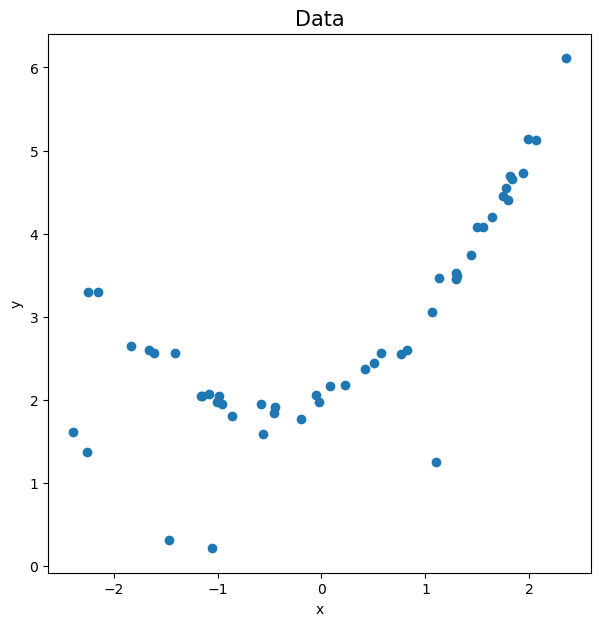

In [66]:
numvals = 50
true_w = 0.5
np.random.seed(21)

xvals = 5*(np.random.random(num_vals) - 0.5)
yvals = true_w*(xvals + xvals**2) + np.random.normal(0, 0.1, numvals)

yvals[int(numvals*0.1):] += 2

plt.figure(figsize=(7,7))
plt.scatter(xvals, yvals)
plt.xlabel('x', fontsize=10)
plt.ylabel('y', fontsize=10)
plt.title('Data', fontsize=15)
plt.show()

# Model

## $\hat{y} = w(x + x^2)$

# Loss Function

## $ L(y,\hat{y}) = \sum_{i=1}^{n}(\hat{y}_i - y_i)^2$

## $ L(y,x,w) = \sum_{i=1}^{n}(wx_i + wx_i^2 - y_i)^2$

## $ \frac{dL}{dw} = \sum_{i=1}^{n}2(x_i + x_i^2)(wx_i + wx_i^2 - y_i)$

In [26]:
def get_loss(yvals,xvlas,w):
    return np.sum((w*xvals + w*xvals*xvals - yvals)**2)

In [34]:
def get_gradient(yvals,xvlas,w):
    grad = np.sum(2*(xvals + xvals**2)*(w*xvals + w*xvals**2 - yvals))
    return grad

Text(0.5, 1.0, 'Loss Function')

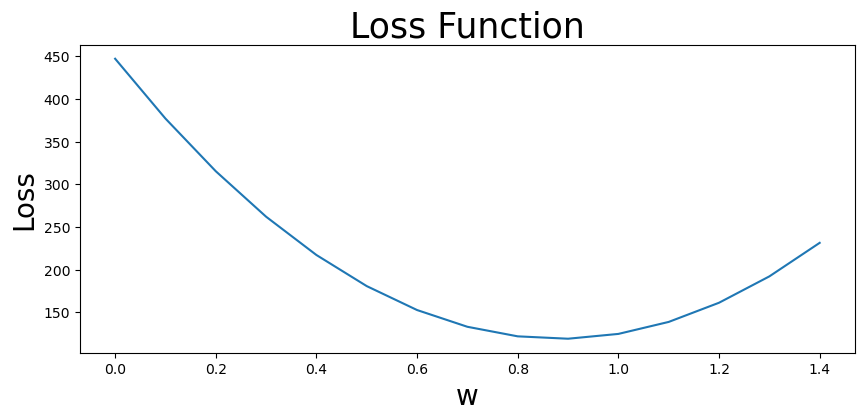

In [30]:
wvals = np.arange(0,1.5,0.1)

lossvals = [get_loss(yvals,xvals,w) for w in wvals]

plt.figure(figsize=(10,4))
plt.plot(wvals,lossvals)
plt.xlabel('w', fontsize=20)
plt.ylabel('Loss', fontsize=20)
plt.title('Loss Function', fontsize=25)

Text(0.5, 1.0, 'Gradient Function')

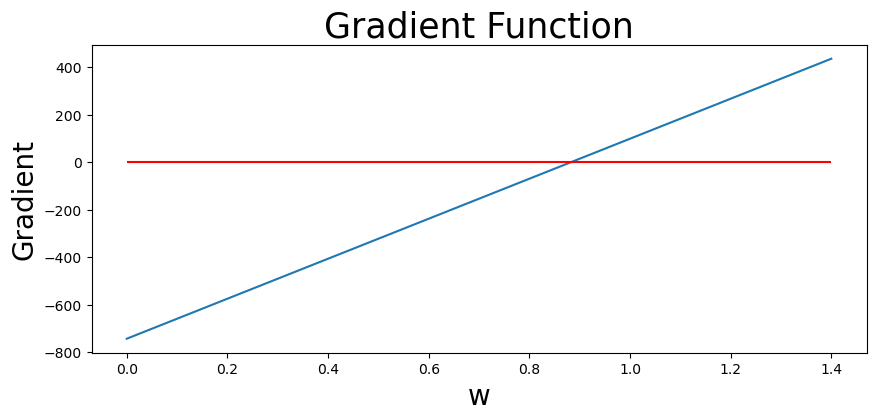

In [38]:
wvals = np.arange(0,1.5,0.1)

gradvals = [get_gradient(yvals,xvals,w) for w in wvals]

plt.figure(figsize=(10,4))
plt.plot(wvals,gradvals)
plt.hlines(y=0,xmax = 1.4,xmin=0,color = 'red')  
plt.xlabel('w', fontsize=20)
plt.ylabel('Gradient', fontsize=20)
plt.title('Gradient Function', fontsize=25)

In [50]:
def perform_gradient_descent(init_w,eta, num_iters,get_gradient):   # passing a function in signature of another function
    
    w_vals = [init_w]
    
    for i in range(num_iters):
        
        # get gradient
        grad = get_gradient(yvals, xvals,w_vals[-1])
        
        # travel in direction of descent of gradient
        w_vals.append(w_vals[-1] - eta*grad)             # check formula w_new = w_old - eta *gradient
        
    return w_vals

Text(0, 0.5, 'w')

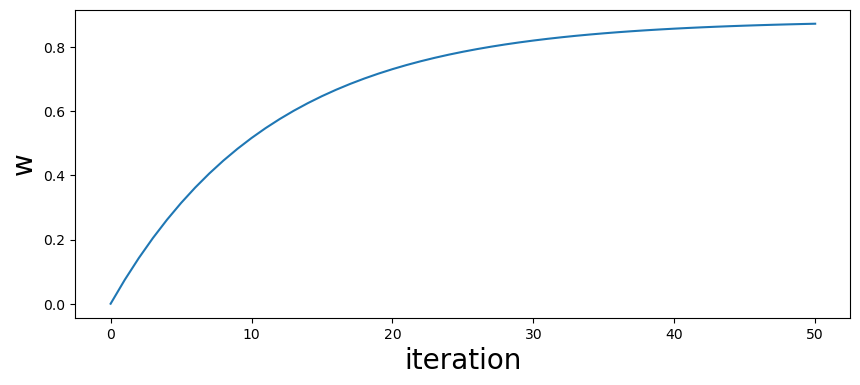

In [53]:
w_vals = perform_gradient_descent(0, 0.0001, 50, get_gradient)

plt.figure(figsize=(10,4))
plt.plot(w_vals)
plt.xlabel('iteration', fontsize=20)
plt.ylabel('w', fontsize=20)

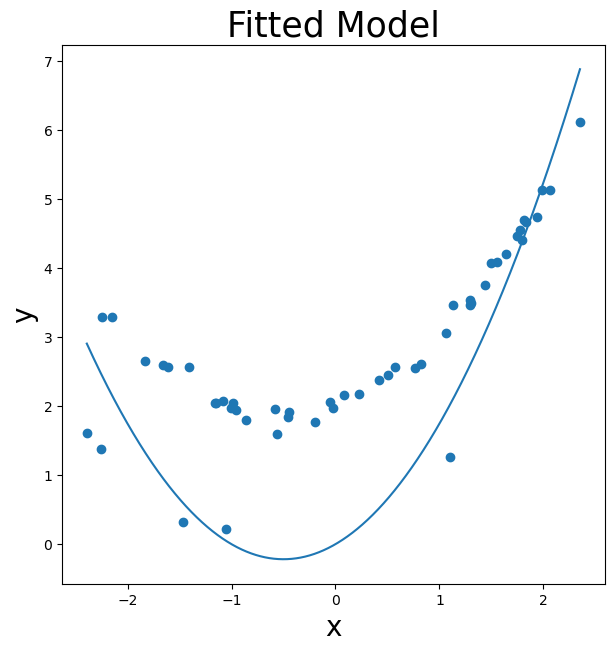

In [67]:
xrange = np.arange(xvals.min(), xvals.max(),0.001)
yvals_pred = w_vals[-1]*(xrange + xrange**2)

plt.figure(figsize=(7,7))
plt.scatter(xvals, yvals)
plt.plot(xrange,yvals_pred)
plt.xlabel('x', fontsize=20)
plt.ylabel('y', fontsize=20)
plt.title('Fitted Model', fontsize=25)
plt.show()